In [1]:
!pip -q install -U timm
import os, gc, math, time, glob, numpy as np, pandas as pd, cv2, torch, torch.nn as nn, torch.nn.functional as F, timm
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, accuracy_score

DEV = "cuda"
COMP = "/kaggle/input/competitions/ai-of-god-5/participant_data"
OUT = "/kaggle/working"

SZ, TAG = 336, "D3S336"
ARCH = "vit_large_patch16_dinov3.lvd1689m"          # needs your Hugging Face token in Kaggle secrets, as before
N_UNFROZEN = 14                         # blocks 10-23 trainable, so the loss reaches blocks 10 and 11
BS = 4 
EPOCHS = 20# more unfrozen blocks use more memory
TAG = "D3S336ml"
LR_TOP, LLD, LR_HEAD, WD, EMA_D = 3e-5, 0.85, 1e-3, 0.05, 0.99
AUX_W = 0.5                                          # weight of the boundary loss
RUN_FOLDS = [0]

GRID = SZ // 16                                      # 21 patches per side
TGT = GRID * 4                                       # boundary target resolution (84)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)
PERMS = [[0, 1, 2], [1, 2, 0], [2, 0, 1], [2, 1, 0]]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 31.7 MB/s eta 0:00:0000:0100:01


In [2]:
df = pd.read_csv(f"{COMP}/train.csv"); te = pd.read_csv(f"{COMP}/sample_submission.csv")
le = LabelEncoder(); y = le.fit_transform(df.animal_class); NC = len(le.classes_)

def resolve(d, n):
    p = f"{COMP}/{d}/{n}"
    if os.path.exists(p): return p
    for e in (".png", ".jpg", ".jpeg"):
        if os.path.exists(p + e): return p + e
    raise FileNotFoundError(p)

def cache(paths, name):
    f = f"{OUT}/{name}_{SZ}.npy"
    if not os.path.exists(f):
        arr = np.zeros((len(paths), SZ, SZ, 3), np.uint8)
        for i, p in enumerate(tqdm(paths)):
            im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB); h, w = im.shape[:2]; s = SZ / max(h, w)
            im = cv2.resize(im, (max(1, round(w*s)), max(1, round(h*s))), interpolation=cv2.INTER_AREA)
            oy, ox = (SZ - im.shape[0])//2, (SZ - im.shape[1])//2
            arr[i, oy:oy+im.shape[0], ox:ox+im.shape[1]] = im
        np.save(f, arr); del arr
    return np.load(f, mmap_mode="r")

Xtr = cache([resolve("train_images", n) for n in df.image_id], "train")
Xte = cache([resolve("test_images", n) for n in te.image_id], "test")
folds = list(StratifiedKFold(5, shuffle=True, random_state=0).split(np.zeros(len(y)), y))
print(Xtr.shape, Xte.shape, NC)

  0%|          | 0/3087 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [7]:
from collections import Counter
DIR = "/kaggle/input/datasets/kebupu/d3l336-dataset"
oof = np.full((len(y), NC), np.nan, np.float32)
for k in range(5):
    oof[np.load(f"{DIR}/va_idx_D3L336_f{k}.npy")] = np.load(f"{DIR}/oof_D3L336_f{k}.npy")
pred = oof.argmax(1); print("OOF acc", (pred == y).mean().round(4), "| errors", int((pred != y).sum()))

c = Counter()
for t, p in zip(y[pred != y], pred[pred != y]): c[tuple(sorted((le.classes_[t], le.classes_[p])))] += 1
print("most confused pairs:", c.most_common(15))
print("classes with most errors:", pd.Series(le.classes_[y[pred != y]]).value_counts().head(12).to_dict())

OOF acc 0.9832 | errors 52
most confused pairs: [(('antelope', 'deer'), 4), (('boar', 'pig'), 4), (('coyote', 'wolf'), 3), (('shark', 'whale'), 2), (('possum', 'rat'), 2), (('pelecaniformes', 'swan'), 2), (('bear', 'wombat'), 2), (('crow', 'eagle'), 2), (('cow', 'reindeer'), 1), (('bison', 'cow'), 1), (('donkey', 'horse'), 1), (('antelope', 'bat'), 1), (('squid', 'starfish'), 1), (('coyote', 'fox'), 1), (('hippopotamus', 'tiger'), 1)]
classes with most errors: {'pig': 5, 'antelope': 3, 'swan': 3, 'beetle': 3, 'hornbill': 2, 'reindeer': 2, 'bee': 2, 'coyote': 2, 'pelecaniformes': 2, 'possum': 2, 'crow': 2, 'wolf': 2}


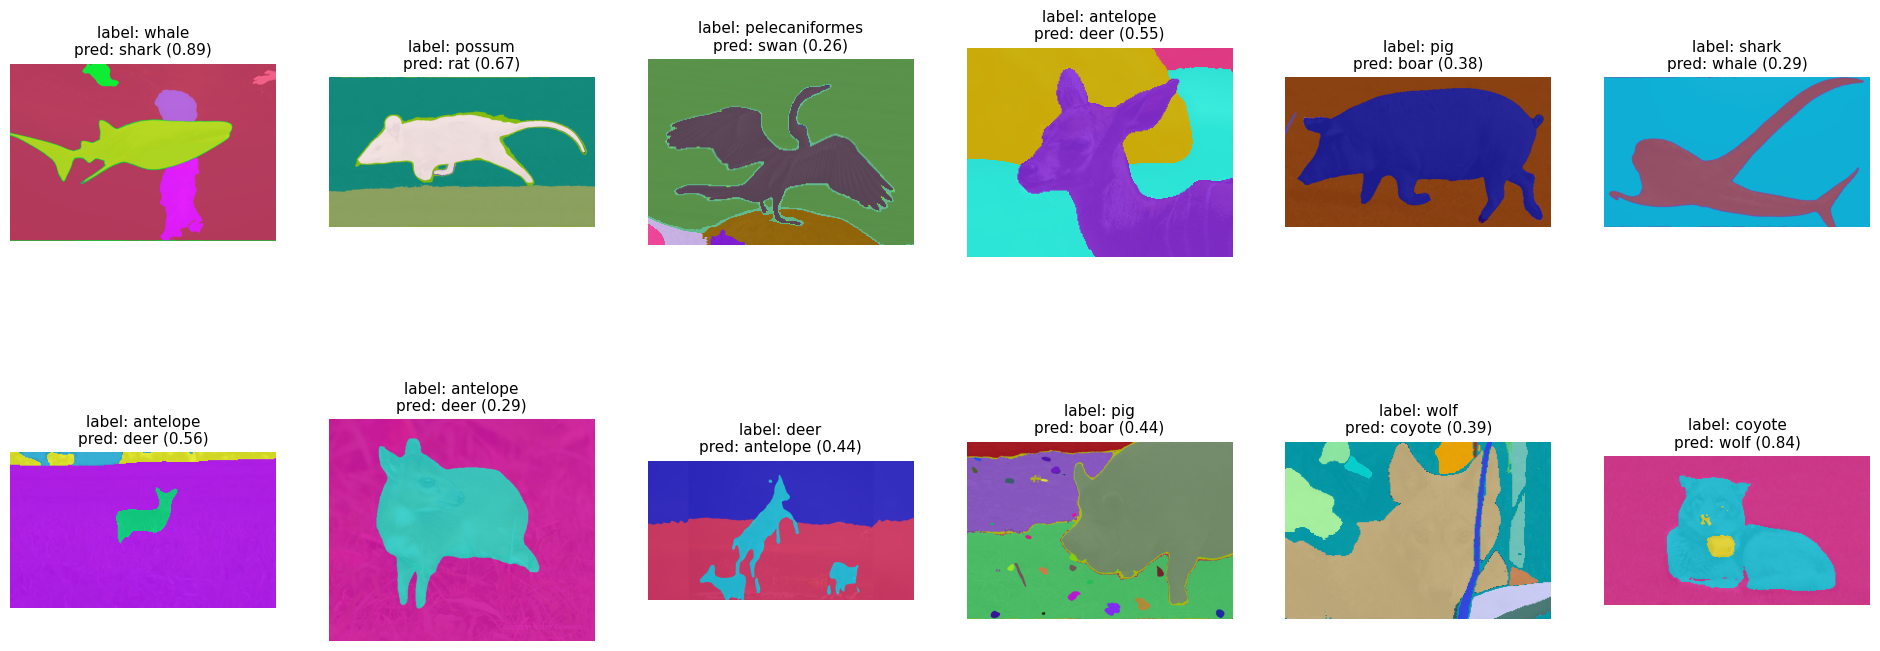

In [8]:
import matplotlib.pyplot as plt
top_pairs = [p for p, _ in c.most_common(6)]
bad = np.where(pred != y)[0]
sel = [i for i in bad if tuple(sorted((le.classes_[y[i]], le.classes_[pred[i]]))) in top_pairs][:12]
fig, ax = plt.subplots(2, 6, figsize=(24, 9))
for a, i in zip(ax.ravel(), sel):
    a.imshow(cv2.cvtColor(cv2.imread(resolve("train_images", df.image_id[i])), cv2.COLOR_BGR2RGB)); a.axis("off")
    a.set_title(f"label: {le.classes_[y[i]]}\npred: {le.classes_[pred[i]]} ({oof[i].max():.2f})", fontsize=11)
plt.show()

In [9]:
Pt = np.mean([np.load(f"{DIR}/test_D3L336_f{k}.npy") for k in range(5)], axis=0)
top2 = np.argsort(-Pt, 1)[:, :2]; unc = np.where(Pt.max(1) < 0.7)[0]
cnt = Counter(tuple(sorted((le.classes_[top2[i, 0]], le.classes_[top2[i, 1]]))) for i in unc)
print(f"uncertain test images (max prob < 0.7): {len(unc)} / {len(Pt)}")
print(cnt.most_common(15))

uncertain test images (max prob < 0.7): 39 / 1179
[(('coyote', 'fox'), 3), (('antelope', 'deer'), 3), (('dolphin', 'whale'), 2), (('shark', 'whale'), 2), (('coyote', 'dog'), 2), (('boar', 'hippopotamus'), 2), (('crow', 'hornbill'), 1), (('rat', 'squirrel'), 1), (('duck', 'swan'), 1), (('boar', 'pig'), 1), (('beetle', 'fly'), 1), (('coyote', 'wolf'), 1), (('goat', 'sheep'), 1), (('cow', 'goat'), 1), (('hornbill', 'pelecaniformes'), 1)]


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
DIR = "/kaggle/input/datasets/kebupu/d3l560-dataset"; FS = 560

def letterbox(p, S):
    im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB); h, w = im.shape[:2]; s = S / max(h, w)
    im = cv2.resize(im, (max(1, round(w*s)), max(1, round(h*s))), interpolation=cv2.INTER_CUBIC)
    c = np.zeros((S, S, 3), np.uint8); oy, ox = (S - im.shape[0])//2, (S - im.shape[1])//2
    c[oy:oy+im.shape[0], ox:ox+im.shape[1]] = im; return c

m = timm.create_model(ARCH, pretrained=True, num_classes=0, img_size=FS).to(DEV).eval()
@torch.no_grad()
def feats_paths(paths, bs=8):
    out = []
    for i in tqdm(range(0, len(paths), bs)):
        x = torch.from_numpy(np.stack([letterbox(p, FS) for p in paths[i:i+bs]])).to(DEV).permute(0, 3, 1, 2).float() / 255
        x = (x - MEAN) / STD; acc = 0
        for fl in (0, 1):
            with torch.autocast("cuda", dtype=torch.float16): ft = m.forward_features(x.flip(3) if fl else x).float()
            acc = acc + torch.cat([ft[:, 0], ft[:, m.num_prefix_tokens:].mean(1)], 1)
        out.append((acc / 2).cpu())
    return torch.cat(out).numpy()

Ftr = feats_paths([resolve("train_images", n) for n in df.image_id]); np.save("/kaggle/working/Ftr560.npy", Ftr)
Fte = feats_paths([resolve("test_images", n) for n in te.image_id]); np.save("/kaggle/working/Fte560.npy", Fte)
del m; gc.collect(); torch.cuda.empty_cache()

# 5-fold OOF for the frozen-feature classifier (same folds as D3L336), then blend
oofA = np.full((len(y), NC), np.nan, np.float32); oofL = np.full((len(y), NC), np.nan, np.float32)
for k, (tr, va) in enumerate(folds):
    sc = StandardScaler().fit(Ftr[tr]); lr = LogisticRegression(C=0.5, max_iter=2000).fit(sc.transform(Ftr[tr]), y[tr])
    oofL[va] = lr.predict_proba(sc.transform(Ftr[va]))
    assert (np.load(f"{DIR}/va_idx_D3L336_f{k}.npy") == va).all()
    oofA[va] = np.load(f"{DIR}/oof_D3L336_f{k}.npy")
print(f"frozen LR  acc {(oofL.argmax(1)==y).mean():.4f} | errors {(oofL.argmax(1)!=y).sum()}")
for w in [0, .1, .2, .3, .5]:
    P = (1-w)*oofA + w*oofL; print(f"blend w_LR={w}: acc {(P.argmax(1)==y).mean():.4f} | errors {(P.argmax(1)!=y).sum()}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.21GB            

model.safetensors: downloading bytes:           |  0.00B            

  0%|          | 0/386 [00:00<?, ?it/s]

  0%|          | 0/148 [00:00<?, ?it/s]

NameError: name 'folds' is not defined

In [23]:
W = 0.2                                                     # your best weight
sc = StandardScaler().fit(Ftr); lr = LogisticRegression(C=0.5, max_iter=2000).fit(sc.transform(Ftr), y)
Pt = np.mean([np.load(f"{DIR}/test_D3L336_f{k}.npy") for k in range(5)], axis=0)
P2 = (1 - W) * Pt + W * lr.predict_proba(sc.transform(Fte))
print("test predictions changed:", int((P2.argmax(1) != Pt.argmax(1)).sum()))
pd.DataFrame({"image_id": te.image_id, "animal_class": le.classes_[P2.argmax(1)]}).to_csv("/kaggle/working/submission_lr.csv", index=False)

test predictions changed: 3


In [24]:
base = oofA.argmax(1) == y
for w in [0.3, 0.5, 0.7, 1.0]:
    P = (1 - w) * oofA + w * oofL; new = P.argmax(1) == y
    print(f"w={w}: fixed {(~base & new).sum()} | broken {(base & ~new).sum()} | errors {(~new).sum()}")

w=0.3: fixed 11 | broken 9 | errors 50
w=0.5: fixed 16 | broken 10 | errors 46
w=0.7: fixed 21 | broken 15 | errors 46
w=1.0: fixed 24 | broken 28 | errors 56


In [13]:
W = 0.5
P2 = (1 - W) * Pt + W * lr.predict_proba(sc.transform(Fte))
print("test predictions changed:", int((P2.argmax(1) != Pt.argmax(1)).sum()))
pd.DataFrame({"image_id": te.image_id, "animal_class": le.classes_[P2.argmax(1)]}).to_csv("/kaggle/working/submission_lr.csv", index=False)

test predictions changed: 6


In [25]:
FS = 672         # rerun the extraction block with FS = 336, then 672; save as Ftr{FS}.npy / Fte{FS}.npy
# ... (same feats_paths code as before, with the new FS)

def lr_oof(Ftr_):
    o = np.full((len(y), NC), np.nan, np.float32)
    for tr, va in folds:
        sc = StandardScaler().fit(Ftr_[tr]); o[va] = LogisticRegression(C=0.5, max_iter=2000).fit(sc.transform(Ftr_[tr]), y[tr]).predict_proba(sc.transform(Ftr_[va]))
    return o
oofs = {fs: lr_oof(np.load(f"/kaggle/working/Ftr{fs}.npy")) for fs in (336, 448, 672)}
for fs, o in oofs.items(): print(fs, "errors", (o.argmax(1) != y).sum())
frozen = np.mean(list(oofs.values()), axis=0)
for w in [0.3, 0.5, 0.7]:
    P = (1 - w) * oofA + w * frozen; print(f"fine-tuned + frozen-multires w={w}: errors {(P.argmax(1) != y).sum()}")

336 errors 71
448 errors 63
672 errors 56
fine-tuned + frozen-multires w=0.3: errors 47
fine-tuned + frozen-multires w=0.5: errors 46
fine-tuned + frozen-multires w=0.7: errors 50


In [26]:
import numpy as np, pandas as pd, os
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

FEATDIR = "/kaggle/working"                       # or the dataset folder holding the Ftr*/Fte* files
DIR = "/kaggle/input/datasets/kebupu/d3l336-dataset"
FS_LIST, W = (336, 448, 672), 0.5

frozen = 0
for fs in FS_LIST:
    assert os.path.exists(f"{FEATDIR}/Ftr{fs}.npy") and os.path.exists(f"{FEATDIR}/Fte{fs}.npy"), f"missing features for {fs}"
    Ftr_, Fte_ = np.load(f"{FEATDIR}/Ftr{fs}.npy"), np.load(f"{FEATDIR}/Fte{fs}.npy")
    sc = StandardScaler().fit(Ftr_)
    lr = LogisticRegression(C=0.5, max_iter=2000).fit(sc.transform(Ftr_), y)       # fit on all 3,087 labeled images
    frozen = frozen + lr.predict_proba(sc.transform(Fte_)) / len(FS_LIST)

ft = np.mean([np.load(f"{DIR}/test_D3L336_f{k}.npy") for k in range(5)], axis=0)
P = (1 - W) * ft + W * frozen
sub = pd.DataFrame({"image_id": te.image_id, "animal_class": le.classes_[P.argmax(1)]})
sub.to_csv("/kaggle/working/submission_ft_frozen.csv", index=False)
print(sub.shape, sub.animal_class.nunique(), "classes | changed vs D3L336 alone:", int((P.argmax(1) != ft.argmax(1)).sum()))

(1179, 2) 72 classes | changed vs D3L336 alone: 6
